# Week 10 Lab: Recommendation Systems (Content-Based and Collaborative Filtering)
**CSE303 Machine Learning | Unit: Recommender Systems | Syllabus: content-based filtering, collaborative filtering**

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**, then an end-to-end **mini project** of your choice (handout: `Week10_Recsys_Project_Menu.docx`).

| Part | Topic | Track |
|---|---|---|
| 1 | The user × item rating matrix and sparsity | core |
| 2 | Content-based filtering (TF-IDF, cosine, user profile) | core |
| 3 | Collaborative filtering (user-based, item-based, mean-centering) | core |
| 4 | Evaluating a recommender (RMSE, precision@k, baselines, leakage) | core |
| 5 | Cold start and a simple hybrid | core |
| 6 | Mini project (end-to-end pipeline) | project |
| 7 | Reflection and capstone link | |

**Rule carried from Weeks 5 and 9:** split first. Anything learned from data (means, similarities, TF-IDF vocabulary) must be computed on **train only**.

**Why this week matters:** Netflix, YouTube, Amazon, Spotify, Swiggy and LinkedIn all run on recommenders. The two ideas you learn here (similar *items* by content, similar *users* by behaviour) are the foundation of every production system, including the deep-learning ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
np.random.seed(1)


## Part 1: The Rating Matrix and Sparsity
A recommender starts from a table with one row per user and one column per item. Most cells are **empty** because nobody has watched everything. Predicting the empty cells is the whole problem.

Below: 12 films (each with a short text description) and 8 users who have rated a few of them (1 to 5).

In [2]:
movies = pd.DataFrame({
 'title':['Cricket Fever','Match Point','Spice Route','Curry Nights','Chip Wars','Quantum Phone',
          'Last Over','Pasta Masters','Robot Uprising','Boundary Line','Street Food Tales','Silicon Dreams'],
 'desc':['cricket team underdog sports tournament victory',
         'tennis rivalry sports championship coach athlete',
         'cooking travel spices chef kitchen street',
         'chef curry kitchen family restaurant cooking',
         'technology startup processor chips rivalry gadgets',
         'technology phone quantum science gadgets future',
         'cricket sports final over pressure team',
         'cooking pasta chef competition kitchen',
         'technology robot science future artificial',
         'cricket sports batsman boundary stadium',
         'cooking street food travel chef stories',
         'technology startup silicon gadgets future']})

users = ['Asha','Bala','Chitra','Dev','Esha','Farid','Gita','Hari']
data = {
 'Asha':  {'Cricket Fever':5,'Match Point':4,'Last Over':5,'Spice Route':1,'Chip Wars':2},
 'Bala':  {'Cricket Fever':5,'Boundary Line':4,'Match Point':5,'Pasta Masters':2,'Quantum Phone':1},
 'Chitra':{'Spice Route':5,'Curry Nights':5,'Pasta Masters':4,'Cricket Fever':1,'Robot Uprising':2},
 'Dev':   {'Curry Nights':4,'Street Food Tales':5,'Spice Route':4,'Last Over':2},
 'Esha':  {'Quantum Phone':5,'Chip Wars':4,'Robot Uprising':5,'Silicon Dreams':5,'Pasta Masters':1},
 'Farid': {'Chip Wars':5,'Silicon Dreams':4,'Quantum Phone':4,'Match Point':2},
 'Gita':  {'Cricket Fever':4,'Curry Nights':4,'Quantum Phone':4,'Street Food Tales':3,'Robot Uprising':3},
 'Hari':  {'Boundary Line':5,'Last Over':4,'Cricket Fever':5,'Spice Route':2,'Silicon Dreams':1},
}
R = pd.DataFrame(np.nan, index=users, columns=movies.title)
for u, d in data.items():
    for m, v in d.items():
        R.loc[u, m] = v
R


title,Cricket Fever,Match Point,Spice Route,Curry Nights,Chip Wars,Quantum Phone,Last Over,Pasta Masters,Robot Uprising,Boundary Line,Street Food Tales,Silicon Dreams
Asha,5.0,4.0,1.0,NaN,2.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
Bala,5.0,5.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,4.0,NaN,NaN
Chitra,1.0,NaN,5.0,5.0,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN
Dev,NaN,NaN,4.0,4.0,NaN,NaN,2.0,NaN,NaN,NaN,5.0,NaN
Esha,NaN,NaN,NaN,NaN,4.0,5.0,NaN,1.0,5.0,NaN,NaN,5.0
Farid,NaN,2.0,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN,4.0
Gita,4.0,NaN,NaN,4.0,NaN,4.0,NaN,NaN,3.0,NaN,3.0,NaN
Hari,5.0,NaN,2.0,NaN,NaN,NaN,4.0,NaN,NaN,5.0,NaN,1.0


In [3]:
n_ratings = int(R.notna().sum().sum())
print('ratings:', n_ratings, 'of', R.size, 'cells')
print('sparsity (share of empty cells):', round(1 - n_ratings / R.size, 3))


ratings: 38 of 96 cells
sparsity (share of empty cells): 0.604


**Predict, then think:** Netflix-scale data has millions of users and tens of thousands of titles. Would you expect the sparsity there to be *lower* or *higher* than here (60%)? What does that mean for methods that need two users to have rated the *same* items?

*Your answer:* I would expect Netflix-scale data to have higher sparsity than here (60%). This is because Netflix has millions of users and tens of thousands of movies, but each user watches and rates only a small fraction of the available movies. Higher sparsity makes traditional Collaborative Filtering more challenging because there are fewer common ratings available to identify similar users.

### Student Practice 1
1. How many ratings does each user have? Each movie?
2. Which movie has the most ratings (the most *popular*)? Which has the highest *average* rating? Are they the same movie?
3. Why is "most popular" a poor recommendation for every user, even though it is easy to compute?

In [4]:
# Write your answer here
print("Ratings per user:")
print(R.count(axis=1))

print("\nRatings per movie:")
print(R.count(axis=0))

rating_counts = R.count(axis=0)
rating_means = R.mean(axis=0)

print("\nMost popular movie:")
print(rating_counts.idxmax(), "-", rating_counts.max(), "ratings")

print("\nHighest average-rated movie:")
print(rating_means.idxmax(), "-", round(rating_means.max(), 2))

print("\nAre they the same movie?")
print(rating_counts.idxmax() == rating_means.idxmax())

print("\nAnswer:")
print("Most popular movies are not suitable for every user because")
print("different users have different interests and preferences.")
print("Popularity-based recommendations ignore individual preferences.")
print("Personalized recommendation systems provide better suggestions.")

Ratings per user:
Asha      5
Bala      5
Chitra    5
Dev       4
Esha      5
Farid     4
Gita      5
Hari      5
dtype: int64

Ratings per movie:
title
Cricket Fever        5
Match Point          3
Spice Route          4
Curry Nights         3
Chip Wars            3
Quantum Phone        4
Last Over            3
Pasta Masters        3
Robot Uprising       3
Boundary Line        2
Street Food Tales    2
Silicon Dreams       3
dtype: int64

Most popular movie:
Cricket Fever - 5 ratings

Highest average-rated movie:
Boundary Line - 4.5

Are they the same movie?
False

Answer:
Most popular movies are not suitable for every user because
different users have different interests and preferences.
Popularity-based recommendations ignore individual preferences.
Personalized recommendation systems provide better suggestions.


## Part 2: Content-Based Filtering
Idea: describe every **item** by its content, describe every **user** by the content of what they liked, and recommend items whose content matches the user's profile. Needs no other users.

Step 1: turn each description into a **TF-IDF** vector (words that appear in few items count more). Step 2: **cosine similarity** between items.

In [5]:
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(movies.desc)           # items x words (sparse)
S_item = cosine_similarity(T)                   # items x items
titles = list(movies.title)

i = titles.index('Cricket Fever')
print(pd.Series(S_item[i], index=titles).sort_values(ascending=False).head(4))


Cricket Fever    1.000
Last Over        0.372
Boundary Line    0.237
Match Point      0.093
dtype: float64


**Predict, then think:** `Chip Wars` is a technology film about rivalry, and `Match Point` is a sports film about rivalry. Will they be more similar to each other than `Chip Wars` is to `Silicon Dreams`? Write your guess, then check it in the practice cell.

Ans: Chip Wars and Silicon Dreams will be more similar to each other than Chip Wars and Match Point.

### Student Practice 2
1. Print the similarity between `Chip Wars` and `Match Point`, and between `Chip Wars` and `Silicon Dreams`. Was your guess right?
2. Which 3 films are most similar to `Spice Route`?

In [6]:
# Write your answer here
i = titles.index('Chip Wars')
j = titles.index('Match Point')
k = titles.index('Silicon Dreams')

print("Chip Wars vs Match Point:", round(S_item[i, j], 3))
print("Chip Wars vs Silicon Dreams:", round(S_item[i, k], 3))

print("Was the guess right?", S_item[i, k] > S_item[i, j])

i = titles.index('Spice Route')

similar_movies = pd.Series(S_item[i], index=titles)
similar_movies = similar_movies.drop('Spice Route')

print("\nTop 3 movies similar to Spice Route:")
print(similar_movies.sort_values(ascending=False).head(3))

Chip Wars vs Match Point: 0.152
Chip Wars vs Silicon Dreams: 0.457
Was the guess right? True

Top 3 movies similar to Spice Route:
Street Food Tales    0.574
Pasta Masters        0.403
Curry Nights         0.355
dtype: float64


### Building a user profile
A user profile is a weighted sum of the vectors of the items they rated. We weight by **rating minus the user's own average**, so a 1-star film pushes the profile *away* from its content and a 5-star film pulls it *toward* it. Then we score unseen items by cosine similarity to the profile.

In [7]:
def user_profile(u):
    r = R.loc[u].dropna()
    w = r - r.mean()                                   # mean-centred weights
    idx = [titles.index(m) for m in r.index]
    return np.asarray(T[idx].T.dot(w.values)).ravel()

def recommend_cb(u, n=3):
    p = user_profile(u)
    scores = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return scores[R.loc[u].isna()].sort_values(ascending=False).head(n)   # unseen only

print('Asha:\n', recommend_cb('Asha'))


Asha:
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


### Student Practice 3
1. Recommend 3 films for `Gita` (she likes sports, cooking and tech). Do the scores look confident? Why or why not?
2. Which of Asha's ratings pulls her profile *away* from cooking content? (Look at the weights `r - r.mean()`.)

In [8]:
# Write your answer here
print("Top 3 recommendations for Gita:")
print(recommend_cb('Gita', 3))

r = R.loc['Gita'].dropna()
w = r - r.mean()

print("\nGita's ratings:")
print(r)

print("\nGita's mean-centred weights:")
print(w)

r = R.loc['Asha'].dropna()
w = r - r.mean()

print("\nAsha's mean-centred weights:")
print(w)

print("\nRatings pulling Asha away from cooking content:")
print(w[w < 0])

Top 3 recommendations for Gita:
Last Over        0.158
Boundary Line    0.100
Match Point      0.039
dtype: float64

Gita's ratings:
title
Cricket Fever        4.0
Curry Nights         4.0
Quantum Phone        4.0
Robot Uprising       3.0
Street Food Tales    3.0
Name: Gita, dtype: float64

Gita's mean-centred weights:
title
Cricket Fever        0.4
Curry Nights         0.4
Quantum Phone        0.4
Robot Uprising      -0.6
Street Food Tales   -0.6
Name: Gita, dtype: float64

Asha's mean-centred weights:
title
Cricket Fever    1.6
Match Point      0.6
Spice Route     -2.4
Chip Wars       -1.4
Last Over        1.6
Name: Asha, dtype: float64

Ratings pulling Asha away from cooking content:
title
Spice Route   -2.4
Chip Wars     -1.4
Name: Asha, dtype: float64


### Deliberate error 1: forgetting to mean-centre
Run the cell, then answer: why does this version recommend things Asha would dislike?

In [9]:
def recommend_cb_raw(u, n=3):
    r = R.loc[u].dropna()                              # WRONG: raw ratings as weights
    idx = [titles.index(m) for m in r.index]
    p = np.asarray(T[idx].T.dot(r.values)).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return s[R.loc[u].isna()].sort_values(ascending=False).head(n)

print('Asha, WRONG (raw weights):\n', recommend_cb_raw('Asha'))
print('Asha, correct (centred)  :\n', recommend_cb('Asha'))


Asha, WRONG (raw weights):
 Boundary Line        0.278
Silicon Dreams       0.092
Street Food Tales    0.058
dtype: float64
Asha, correct (centred)  :
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


*Your answer (one line):*

Ans: This version uses Asha's raw ratings (1-5) instead of mean-centred ratings as weights. Because all raw ratings are positive, even movies Asha dislikes contribute positively to her user profile.

## Part 3: Collaborative Filtering
Idea: **ignore content entirely**. Find users who rate like you and recommend what they liked. Works for any item type (a song, a job, a drug), but needs overlapping ratings.

Key steps for **user-based** CF:
1. Mean-centre each user's ratings (a harsh rater's 4 equals a generous rater's 5).
2. Compute user-user similarity on the centred matrix.
3. Predict: $\hat r_{u,m}=\bar r_u+\dfrac{\sum_{v} sim(u,v)\,(r_{v,m}-\bar r_v)}{\sum_{v}|sim(u,v)|}$ over the top-k similar users who rated $m$.

In [10]:
def build_user_cf(R_train):
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0)            # centred; unrated -> 0 = "no opinion"
    sim = pd.DataFrame(cosine_similarity(C), index=R_train.index, columns=R_train.index)
    return means, sim

def predict_user_cf(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    if len(raters) == 0:
        return means[u]                                  # nobody rated it: fall back to user mean
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[s.index, m] - means[s.index])).sum() / s.abs().sum()

means, sim_u = build_user_cf(R)
print(sim_u.round(2))
print()
print('Asha  -> Boundary Line :', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))
print('Gita  -> Pasta Masters :', round(predict_user_cf(R, means, sim_u, 'Gita', 'Pasta Masters'), 2))


        Asha  Bala  Chitra   Dev  Esha  Farid  Gita  Hari
Asha    1.00  0.27   -0.58 -0.43  0.00  -0.35  0.16  0.52
Bala    0.27  1.00   -0.35  0.00  0.14  -0.43 -0.08  0.27
Chitra -0.58 -0.35    1.00  0.10 -0.25   0.00  0.13 -0.46
Dev    -0.43  0.00    0.10  1.00  0.00   0.00 -0.27 -0.18
Esha    0.00  0.14   -0.25  0.00  1.00   0.07 -0.05 -0.19
Farid  -0.35 -0.43    0.00  0.00  0.07   1.00  0.04 -0.08
Gita    0.16 -0.08    0.13 -0.27 -0.05   0.04  1.00  0.16
Hari    0.52  0.27   -0.46 -0.18 -0.19  -0.08  0.16  1.00

Asha  -> Boundary Line : 4.66
Gita  -> Pasta Masters : 4.2


**Predict, then think:** Asha and Hari both love cricket films. Their similarity above should be the largest positive value in Asha's row. Is it? And what sign do you expect between Asha and Chitra (cooking fan who disliked `Cricket Fever`)?

Ans: Asha and Hari both enjoy cricket movies, so we expect their similarity score to be the largest positive value in Asha's similarity row. Asha and Chitra are expected to have negative similarity because their preferences differ. Asha likes cricket movies, whereas Chitra dislikes Cricket Fever and prefers cooking movies.

### Student Practice 4
1. List the 3 most similar users to `Asha` and the 3 *least* similar. Do they match your intuition?
2. Predict `Esha -> Match Point` and `Dev -> Cricket Fever`. For each, which users were used?
3. **Item-based CF:** build item-item similarity from the *centred* matrix (centre by user, then take cosine between *columns*) and predict `Asha -> Boundary Line` as the similarity-weighted average of Asha's own ratings on the most similar rated items. Compare with the user-based answer.

In [11]:
# Write your answer here

print("Most similar users to Asha:")
print(sim_u.loc['Asha'].drop('Asha').sort_values(ascending=False).head(3))

print("\nLeast similar users to Asha:")
print(sim_u.loc['Asha'].drop('Asha').sort_values().head(3))

def show_prediction(u, m, k=3):
    prediction = predict_user_cf(R, means, sim_u, u, m, k)

    raters = R[m].dropna().index.difference([u])
    selected = sim_u.loc[u, raters].sort_values(
        ascending=False
    ).head(k)

    selected = selected[selected > 0]

    print(f"\n{u} -> {m}: {round(prediction, 2)}")
    print("Users used:", list(selected.index))


show_prediction('Esha', 'Match Point')
show_prediction('Dev', 'Cricket Fever')

means_item = R.mean(axis=1)
C = R.sub(means_item, axis=0).fillna(0)

sim_item = pd.DataFrame(
    cosine_similarity(C.T),
    index=R.columns,
    columns=R.columns
)

def predict_item_cf(R, sim_item, u, m, k=3):
    rated = R.loc[u].dropna().index

    s = sim_item.loc[m, rated].sort_values(
        ascending=False
    ).head(k)

    s = s[s > 0]

    if len(s) == 0:
        return R.loc[u].mean()

    prediction = (
        s * R.loc[u, s.index]
    ).sum() / s.sum()

    return prediction


item_prediction = predict_item_cf(
    R, sim_item, 'Asha', 'Boundary Line'
)

user_prediction = predict_user_cf(
    R, means, sim_u, 'Asha', 'Boundary Line'
)

print("\nItem-based CF prediction:")
print(round(item_prediction, 2))

print("\nUser-based CF prediction:")
print(round(user_prediction, 2))

Most similar users to Asha:
Hari    0.521
Bala    0.267
Gita    0.161
Name: Asha, dtype: float64

Least similar users to Asha:
Chitra   -0.582
Dev      -0.429
Farid    -0.354
Name: Asha, dtype: float64

Esha -> Match Point: 4.54
Users used: ['Bala', 'Farid']

Dev -> Cricket Fever: 1.35
Users used: ['Chitra']

Item-based CF prediction:
4.77

User-based CF prediction:
4.66


### Deliberate error 2: treating "unrated" as "rated 0"
Run the cell. Compare the two similarity rows for Asha. Why is filling gaps with 0 on the *raw* matrix wrong?

In [12]:
sim_raw0 = pd.DataFrame(cosine_similarity(R.fillna(0)), index=users, columns=users)   # WRONG
print('raw, gaps=0 :', sim_raw0.loc['Asha'].drop('Asha').round(2).to_dict())
print('centred     :', sim_u.loc['Asha'].drop('Asha').round(2).to_dict())


raw, gaps=0 : {'Bala': 0.63, 'Chitra': 0.14, 'Dev': 0.21, 'Esha': 0.1, 'Farid': 0.27, 'Gita': 0.29, 'Hari': 0.66}
centred     : {'Bala': 0.27, 'Chitra': -0.58, 'Dev': -0.43, 'Esha': 0.0, 'Farid': -0.35, 'Gita': 0.16, 'Hari': 0.52}


*Your answer (one or two lines):*

Ans: Filling missing ratings with 0 in the raw matrix incorrectly treats unrated movies as actual zero ratings, distorting cosine similarity. Mean-centering captures users' preferences relative to their average rating, while missing values filled with 0 represent no opinion.

## Part 4: Evaluating a Recommender
You cannot judge a recommender on ratings it has already seen. **Hold out some known ratings, hide them, predict them, compare.**

- **RMSE** for rating prediction: $\sqrt{\frac1n\sum(\hat r-r)^2}$. Lower is better.
- Always compare with **baselines**: the global mean, and each user's own mean. A model that cannot beat these is not learning anything useful.

Our toy matrix has only 38 ratings, too few to evaluate honestly. So we switch to a **generated** dataset with the same structure: 60 users, 30 films in three genres, about 35% of cells observed, and each user having a favourite genre. (In your project you will use real data.)

In [13]:
def make_data(n_users=60, n_items=30, density=0.35, seed=1):
    rng = np.random.RandomState(seed)
    vocab = {'sports':  ['cricket','match','team','stadium','batsman','tennis','coach','tournament'],
             'cooking': ['chef','kitchen','curry','pasta','spices','restaurant','recipe','street'],
             'tech':    ['phone','processor','startup','gadgets','robot','battery','laptop','science']}
    genres, common = list(vocab), ['new','story','family','final','night','world']
    names = [f'Film{i:02d}' for i in range(n_items)]
    g_item = [genres[i % 3] for i in range(n_items)]
    desc = [' '.join(list(rng.choice(vocab[g], 3, replace=False)) + list(rng.choice(common, 1))) for g in g_item]
    ub, ib = rng.normal(0, 0.3, n_users), rng.normal(0, 0.2, n_items)
    fav = rng.randint(0, 3, n_users)
    Rb = pd.DataFrame(np.nan, index=[f'U{u:02d}' for u in range(n_users)], columns=names)
    for u in range(n_users):
        for i in range(n_items):
            if rng.rand() < density:
                aff = 1.6 if genres.index(g_item[i]) == fav[u] else -1.0
                r = 3 + aff + ub[u] + ib[i] + rng.normal(0, 0.5)
                Rb.iloc[u, i] = float(np.clip(np.round(r), 1, 5))
    return Rb, pd.DataFrame({'title': names, 'desc': desc, 'genre': g_item})

Rb, items = make_data()
print('ratings:', int(Rb.notna().sum().sum()), '| sparsity:', round(1 - Rb.notna().sum().sum() / Rb.size, 3))
print('fewest ratings by one user:', int(Rb.notna().sum(axis=1).min()))
items.head(4)


ratings: 609 | sparsity: 0.662
fewest ratings by one user: 4


,title,desc,genre
0,Film00,tournament team match world,sports
1,Film01,curry pasta spices story,cooking
2,Film02,processor laptop gadgets night,tech
3,Film03,cricket tournament match new,sports


In [14]:
# Content similarity for the generated films, as a labelled table (rows/cols = film names)
tfidf_b = TfidfVectorizer().fit(items.desc)
Tb = tfidf_b.transform(items.desc)
S_b = pd.DataFrame(cosine_similarity(Tb), index=items.title, columns=items.title)

def predict_cb(R_train, S, u, m, k=3):
    """Content-based rating prediction: user's mean + similarity-weighted centred ratings of content-similar rated items."""
    rated = R_train.loc[u].dropna().index.difference([m])
    sims = S.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]
    mu = R_train.loc[u].mean()
    if len(sims) == 0:
        return mu
    return mu + (sims * (R_train.loc[u, sims.index] - mu)).sum() / sims.abs().sum()

def rmse(pred, true):
    pred, true = np.array(pred), np.array(true)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

# hold out 20% of the known ratings (split the RATINGS, not the users)
rng = np.random.RandomState(1)
pairs = [(u, m) for u in Rb.index for m in Rb.columns if not np.isnan(Rb.loc[u, m])]
test_pairs = [pairs[i] for i in rng.choice(len(pairs), size=int(0.2 * len(pairs)), replace=False)]
Rb_train = Rb.copy()
for u, m in test_pairs:
    Rb_train.loc[u, m] = np.nan                                   # hide the test ratings
true = [Rb.loc[u, m] for u, m in test_pairs]
print('train ratings:', int(Rb_train.notna().sum().sum()), '| test ratings:', len(test_pairs))

means_tr, sim_tr = build_user_cf(Rb_train)                        # fitted on TRAIN only
gmean = np.nanmean(Rb_train.values)

p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]

print('RMSE global mean :', round(rmse(p_global, true), 3))
print('RMSE user mean   :', round(rmse(p_user, true), 3))
print('RMSE user-CF k=5 :', round(rmse(p_cf, true), 3))


train ratings: 488 | test ratings: 121
RMSE global mean : 1.354
RMSE user mean   : 1.499
RMSE user-CF k=5 : 1.169


**Predict, then think:** the user-mean baseline can be *worse* than the global mean. Why might that happen when each user has only about 10 ratings, and the user's ratings come mostly from their favourite or least-favourite genre?

*Your answer:* The user-mean baseline can be worse than the global mean because each user's mean is calculated from only a few ratings (around 10), making it less reliable. If those ratings mostly come from their favourite or least-favourite genre, the user's mean becomes biased and may not represent their overall rating behaviour.

### Student Practice 5
1. Add **item-based CF** (reuse `predict_item_cf`, with an item-item similarity built from `Rb_train` only) and **content-based** (`predict_cb` with `S_b`). Report RMSE for all five methods in one table.
2. Try `k` in [1, 3, 5, 10, 20] for user-CF. Plot RMSE against k. Which k would you pick? What happens at k=1?
3. **Precision@3:** for each user with at least one held-out rating of 4 or more, recommend the top 3 unseen items by user-CF prediction (using `Rb_train`); count how many of that user's held-out high ratings appear in the top 3. Report the mean over those users.

RMSE Comparison:
       Method  RMSE
  Global Mean 1.354
    User Mean 1.499
User-based CF 1.169
Item-based CF 1.070
Content-based 1.135

RMSE for different K values:
k=1: RMSE=1.356
k=3: RMSE=1.203
k=5: RMSE=1.169
k=10: RMSE=1.179
k=20: RMSE=1.180


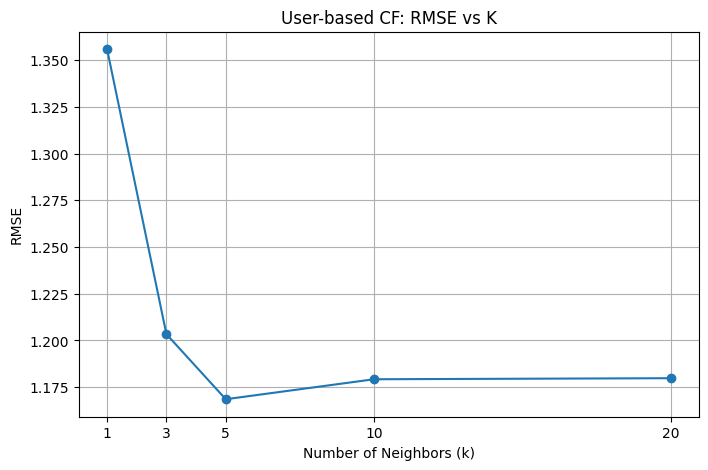

Best K: 5

User: U00
Top 3 recommendations: ['Film03', 'Film00', 'Film15']
Relevant movies: ['Film00']
Hits: 1
Precision@3: 0.333

User: U02
Top 3 recommendations: ['Film23', 'Film02', 'Film29']
Relevant movies: ['Film02']
Hits: 1
Precision@3: 0.333

User: U04
Top 3 recommendations: ['Film02', 'Film29', 'Film26']
Relevant movies: ['Film29']
Hits: 1
Precision@3: 0.333

User: U05
Top 3 recommendations: ['Film08', 'Film02', 'Film29']
Relevant movies: ['Film23']
Hits: 0
Precision@3: 0.0

User: U08
Top 3 recommendations: ['Film02', 'Film17', 'Film05']
Relevant movies: ['Film18', 'Film09']
Hits: 0
Precision@3: 0.0

User: U10
Top 3 recommendations: ['Film02', 'Film08', 'Film14']
Relevant movies: ['Film14']
Hits: 1
Precision@3: 0.333

User: U11
Top 3 recommendations: ['Film02', 'Film08', 'Film26']
Relevant movies: ['Film05']
Hits: 0
Precision@3: 0.0

User: U13
Top 3 recommendations: ['Film02', 'Film23', 'Film17']
Relevant movies: ['Film26']
Hits: 0
Precision@3: 0.0

User: U14
Top 3 recommendat

In [15]:
# Write your answer here

C_item = Rb_train.sub(Rb_train.mean(axis=1), axis=0).fillna(0)

sim_item_b = pd.DataFrame(
    cosine_similarity(C_item.T),
    index=Rb_train.columns,
    columns=Rb_train.columns
)

def predict_item_cf_b(R_train, sim_item, u, m, k=5):
    rated = R_train.loc[u].dropna().index

    sims = sim_item.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]

    if len(sims) == 0:
        return R_train.loc[u].mean()

    return (
        sims * R_train.loc[u, sims.index]
    ).sum() / sims.sum()


p_global = [gmean for u, m in test_pairs]

p_user = [means_tr[u] for u, m in test_pairs]

p_user_cf = [
    predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5)
    for u, m in test_pairs
]

p_item_cf = [
    predict_item_cf_b(Rb_train, sim_item_b, u, m, k=5)
    for u, m in test_pairs
]

p_content = [
    predict_cb(Rb_train, S_b, u, m, k=5)
    for u, m in test_pairs
]

results = pd.DataFrame({
    'Method': [
        'Global Mean',
        'User Mean',
        'User-based CF',
        'Item-based CF',
        'Content-based'
    ],
    'RMSE': [
        rmse(p_global, true),
        rmse(p_user, true),
        rmse(p_user_cf, true),
        rmse(p_item_cf, true),
        rmse(p_content, true)
    ]
})

print("RMSE Comparison:")
print(results.round(3).to_string(index=False))

k_values = [1, 3, 5, 10, 20]
k_rmse = []

for k in k_values:
    predictions = [
        predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=k)
        for u, m in test_pairs
    ]

    score = rmse(predictions, true)
    k_rmse.append(score)

print("\nRMSE for different K values:")
for k, score in zip(k_values, k_rmse):
    print(f"k={k}: RMSE={score:.3f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, k_rmse, marker='o')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('RMSE')
plt.title('User-based CF: RMSE vs K')
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = k_values[np.argmin(k_rmse)]
print("Best K:", best_k)

test_df = pd.DataFrame(test_pairs, columns=['user', 'movie'])
test_df['actual_rating'] = true

eligible_users = []

for u, group in test_df.groupby('user'):
    if (group['actual_rating'] >= 4).any():
        eligible_users.append(u)

precision_scores = []
hit_counts = []

for u in eligible_users:

    relevant = set(
        test_df[
            (test_df['user'] == u) &
            (test_df['actual_rating'] >= 4)
        ]['movie']
    )

    unseen = Rb_train.loc[u][Rb_train.loc[u].isna()].index

    scores = pd.Series({
        m: predict_user_cf(
            Rb_train, means_tr, sim_tr, u, m, k=5
        )
        for m in unseen
    })

    top3 = scores.sort_values(ascending=False).head(3).index

    hits = len(set(top3) & relevant)

    hit_counts.append(hits)
    precision_scores.append(hits / 3)

    print(f"\nUser: {u}")
    print("Top 3 recommendations:", list(top3))
    print("Relevant movies:", list(relevant))
    print("Hits:", hits)
    print("Precision@3:", round(hits / 3, 3))

print("\nEligible users:", len(eligible_users))
print("Mean relevant hits:", round(np.mean(hit_counts), 3))
print("Mean Precision@3:", round(np.mean(precision_scores), 3))


### Deliberate error 3: data leakage
The cell below computes the user similarities and means from the **full** matrix (including the hidden test ratings), then "predicts" them. Run it, compare with the honest RMSE above, and explain the gap. Would this error be visible if you only looked at the final number?

In [16]:
means_leak, sim_leak = build_user_cf(Rb)                       # WRONG: sees the test ratings
p_leak = [predict_user_cf(Rb_train, means_leak, sim_leak, u, m, k=5) for u, m in test_pairs]
print('leaky RMSE :', round(rmse(p_leak, true), 3))
print('honest RMSE:', round(rmse(p_cf, true), 3))


leaky RMSE : 0.621
honest RMSE: 1.169


*Your answer (one or two lines):* The leaky RMSE is usually lower because the model indirectly uses test ratings while calculating user means and similarities. This is data leakage, and it cannot be identified by looking at the final RMSE alone.

## Part 5: Cold Start and a Simple Hybrid
- **New user** (no ratings): CF has nothing to compare. **New item** (no ratings): CF cannot score it. Content-based can handle a new *item* because it only needs the description.
- A **hybrid** blends both: $\hat r = \alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$.

In [17]:
# A brand-new film: we know its text, nobody has rated it
new_desc = 'cricket match stadium team new'
sims_new = pd.Series(cosine_similarity(tfidf_b.transform([new_desc]), Tb).ravel(), index=items.title)
print('New film is most similar to:', list(sims_new.sort_values(ascending=False).head(3).index))
print('Their genres:', [items.set_index('title').genre[t] for t in sims_new.sort_values(ascending=False).head(3).index])


New film is most similar to: ['Film15', 'Film03', 'Film24']
Their genres: ['sports', 'sports', 'sports']


### Student Practice 6
1. Compute hybrid RMSE for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ using `p_cf` and `p_cb`. Which blend is best?
2. A user signs up and has rated **nothing**. Write a fallback recommender (hint: highest average rating among items with at least 3 ratings). State one weakness.
3. A brand-new film has **zero** ratings. Which of the three models (user-CF, item-CF, content-based) can still score it, and why?

In [18]:
# Write your answer here

p_cb = [
    predict_cb(Rb_train, S_b, u, m, k=5)
    for u, m in test_pairs
]

alphas = [0, 0.25, 0.5, 0.75, 1]
hybrid_results = []

for alpha in alphas:
    p_hybrid = [
        alpha * cf + (1 - alpha) * cb
        for cf, cb in zip(p_cf, p_cb)
    ]

    score = rmse(p_hybrid, true)
    hybrid_results.append(score)

    print(f"Alpha={alpha}: RMSE={score:.3f}")

best_alpha = alphas[np.argmin(hybrid_results)]
print("\nBest alpha:", best_alpha)

def fallback_recommend(R_train, n=3):
    counts = R_train.count(axis=0)

    averages = R_train.mean(axis=0)

    popular = averages[counts >= 3]

    return popular.sort_values(ascending=False).head(n)


print("\nFallback recommendations for new user:")
print(fallback_recommend(Rb_train, 3))

print("\nNew film with zero ratings:")

print("User-based CF: Cannot score it because no users have rated it.")

print("Item-based CF: Cannot calculate meaningful rating-based similarity.")

print("Content-based: Can score it using its description and TF-IDF similarity.")

print("\nConclusion: Content-based filtering handles new films.")


Alpha=0: RMSE=1.135
Alpha=0.25: RMSE=1.100
Alpha=0.5: RMSE=1.093
Alpha=0.75: RMSE=1.117
Alpha=1: RMSE=1.169

Best alpha: 0.5

Fallback recommendations for new user:
Film11    3.50
Film12    3.25
Film05    3.20
dtype: float64

New film with zero ratings:
User-based CF: Cannot score it because no users have rated it.
Item-based CF: Cannot calculate meaningful rating-based similarity.
Content-based: Can score it using its description and TF-IDF similarity.

Conclusion: Content-based filtering handles new films.


# Part 6: Mini Project (End-to-End Pipeline)
Pick **one topic** from the handout `Week10_Recsys_Project_Menu.docx` (or propose your own with instructor approval). Work in a pair.

Every project must contain these stages, each as a clearly titled section of your notebook:

1. **Problem and users:** who is the user, what is being recommended, what decision does it support.
2. **Data:** source link, size, cleaning steps, sparsity number.
3. **EDA:** rating/interaction distribution, popularity long tail, at least two plots.
4. **Content-based model:** item features (TF-IDF or tags), cosine similarity, user profile.
5. **Collaborative model:** user-based or item-based with mean-centering.
6. **Evaluation:** honest split (no leakage), RMSE or precision@k, with baselines, in one results table.
7. **Cold-start / hybrid:** show how a new item or user is handled, or a blended model.
8. **Demo:** a function `recommend(user_or_item, n)` that prints readable results.
9. **README:** problem, data, results table, limitations, how to run.

Submit under `labs/week10_recsys/<team_name>/` on GitHub. See the handout for the rubric and CV-bullet guide.

## Part 7: Reflection (2 to 3 lines each)
1. When would you choose content-based over collaborative filtering, and vice versa?
2. Why do we mean-centre ratings? Use your Deliberate error 2 result.
3. What is the *filter bubble* problem, and which of the two methods makes it worse?
4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online (clicks, watch time) that RMSE cannot show?
5. Name one real product that uses a hybrid, and what each half contributes.
6. **Capstone link (Milestone, Week 10):** could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric. If no, justify.

*Submit this notebook to GitHub under `labs/week10_recsys/`.*

1. I would choose content-based filtering when item descriptions or features are available, especially for new items with no ratings. I would choose collaborative filtering when sufficient user-rating data is available because it can discover preferences from similar users.
2. Mean-centering removes individual differences in users' average rating scales and captures their preferences relative to their own average. Our deliberate error experiment showed that filling missing raw ratings with zero produces misleading similarity scores.
3. A filter bubble occurs when users repeatedly receive recommendations similar to their existing interests, limiting exposure to new ideas and genres. Content-based filtering can make it worse because it continuously recommends items similar to what users already like.
4. The improvement is:
{Improvement} = RMSE{global}-RMSE{honest}
A lower RMSE alone is not enough to ship. I would also measure clicks, watch time, completion rate, user engagement and retention through online A/B testing.
5. Netflix uses a combination of recommendation approaches. Collaborative signals help identify viewing patterns among similar users, while content information helps identify similarities between movies and shows to generate personalized recommendations.
6. Yes. In a Smart Farming Advisory System (KrishiMitra), a recommender could suggest suitable crops or fertilizers.
- User: Farmer.
- Item: Crop or fertilizer recommendation.
- Inputs: Soil properties, weather conditions and previous crop information.
- Metric: Precision@3 and recommendation accuracy.
This could help farmers receive recommendations suited to their field conditions.